# TA-06 Random Forest: Prediksi Churn Nasabah Kartu Kredit

**Mata kuliah:** Pembelajaran Mesin (Modul 06: Algoritma Random Forest)
**Penulis:** Selsa Shafana Alfiyani (NIM 301240041), Teknik Informatika, Universitas Bale Bandung
**Dataset:** Credit Card Customers (Kaggle), file `BankChurners.csv` di folder `data/`
**Target:** `Churn` (1 = nasabah berhenti, 0 = nasabah masih aktif)

## Isi notebook
1. Persiapan dan pemuatan data
2. Pengecekan kualitas data dan pembersihan
3. Analisis awal: ketidakseimbangan kelas dan perbandingan antar kelas
4. Pembagian data, encoding, dan bobot kelas
5. Skenario A: pengaruh jumlah pohon (`n_estimators`)
6. Skenario B: pengaruh kedalaman pohon (`max_depth`)
7. Model terbaik dan evaluasi akhir (dengan hitungan manual)
8. Contoh hitungan manual satu pemisahan (Gini) dan voting pohon
9. Feature importance dan insight bisnis
10. Kesimpulan
11. Menyimpan model untuk aplikasi web

**Cara pakai:** letakkan `BankChurners.csv` di folder `data/`, lalu klik **Run All**. Semua analisis, interpretasi, dan kesimpulan ditulis otomatis dari hasil run, jadi angkanya selalu cocok dengan grafik dan tabel.

## 1. Persiapan dan pemuatan data
Sel pertama memuat library dan membuat beberapa fungsi bantu kecil, misalnya untuk menulis angka dengan koma desimal dan menampilkan teks analisis sebagai Markdown.

In [1]:
# 1. Import library dan pengaturan awal
import os
import json
import warnings
import platform
import joblib
import numpy as np
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt
import sklearn
from IPython.display import display, Markdown
from sklearn.model_selection import train_test_split
from sklearn.ensemble import RandomForestClassifier
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder
from sklearn.pipeline import Pipeline
from sklearn.utils.class_weight import compute_class_weight
from sklearn.metrics import (accuracy_score, classification_report, confusion_matrix,
                             f1_score, roc_auc_score, roc_curve)

warnings.filterwarnings("ignore")
os.makedirs("model", exist_ok=True)
os.makedirs("static/img", exist_ok=True)
RANDOM_STATE = 42
sns.set_theme(style="whitegrid")


def fmt(x, d=2):
    # angka dengan koma desimal, contoh 95,66
    return f"{x:.{d}f}".replace(".", ",")


def poin(x):
    # selisih bertanda, contoh +1,48
    return f"{x:+.2f}".replace(".", ",")


def ribuan(x):
    # pemisah ribuan titik, contoh 10.127
    return f"{int(round(x)):,}".replace(",", ".")


def tulis(teks):
    # tampilkan teks sebagai Markdown di output sel
    display(Markdown(teks))


print("Python       :", platform.python_version())
print("scikit-learn :", sklearn.__version__)
print("pandas       :", pd.__version__)

Python       : 3.12.3
scikit-learn : 1.9.1
pandas       : 3.0.6


In [2]:
# 2. Muat dataset
lokasi = [p for p in ["data/BankChurners.csv", "BankChurners.csv", "../data/BankChurners.csv"]
          if os.path.exists(p)]
if not lokasi:
    raise FileNotFoundError("BankChurners.csv tidak ditemukan. Taruh di folder data/ lalu jalankan ulang.")

df = pd.read_csv(lokasi[0])
print("Lokasi file :", lokasi[0])
print("Ukuran data :", df.shape)
df.head()

Lokasi file : data/BankChurners.csv
Ukuran data : (10127, 23)


,CLIENTNUM,Attrition_Flag,Customer_Age,Gender,Dependent_count,Education_Level,Marital_Status,Income_Category,Card_Category,Months_on_book,...,Credit_Limit,Total_Revolving_Bal,Avg_Open_To_Buy,Total_Amt_Chng_Q4_Q1,Total_Trans_Amt,Total_Trans_Ct,Total_Ct_Chng_Q4_Q1,Avg_Utilization_Ratio,Naive_Bayes_Classifier_Attrition_Flag_Card_Category_Contacts_Count_12_mon_Dependent_count_Education_Level_Months_Inactive_12_mon_1,Naive_Bayes_Classifier_Attrition_Flag_Card_Category_Contacts_Count_12_mon_Dependent_count_Education_Level_Months_Inactive_12_mon_2
0,768805383,Existing Customer,45,M,3,High School,Married,$60K - $80K,Blue,39,...,12691.0,777,11914.0,1.335,1144,42,1.625,0.061,0.000093,0.99991
1,818770008,Existing Customer,49,F,5,Graduate,Single,Less than $40K,Blue,44,...,8256.0,864,7392.0,1.541,1291,33,3.714,0.105,0.000057,0.99994
2,713982108,Existing Customer,51,M,3,Graduate,Married,$80K - $120K,Blue,36,...,3418.0,0,3418.0,2.594,1887,20,2.333,0.000,0.000021,0.99998
3,769911858,Existing Customer,40,F,4,High School,Unknown,Less than $40K,Blue,34,...,3313.0,2517,796.0,1.405,1171,20,2.333,0.760,0.000134,0.99987
4,709106358,Existing Customer,40,M,3,Uneducated,Married,$60K - $80K,Blue,21,...,4716.0,0,4716.0,2.175,816,28,2.500,0.000,0.000022,0.99998


## 2. Pengecekan kualitas data dan pembersihan
Sebelum dipakai, data dicek dulu: tipe kolom, nilai kosong, data ganda, dan nilai `Unknown` pada kolom kategori.

In [3]:
# 3. Cek kualitas data
print("Jumlah kolom per tipe data:")
print(df.dtypes.value_counts(), "\n")

n_missing = int(df.isnull().sum().sum())
n_dupe = int(df.duplicated().sum())
print("Total missing value :", n_missing)
print("Data duplikat       :", n_dupe)

unknown = {}
for k in df.select_dtypes(include="object").columns:
    n = int((df[k] == "Unknown").sum())
    if n > 0:
        unknown[k] = n
print("Nilai Unknown       :", unknown)

teks = (f"**Hasil pengecekan.** Data berisi {ribuan(len(df))} baris dan {df.shape[1]} kolom. "
        f"Jumlah nilai kosong {n_missing} dan data ganda {n_dupe}, ")
teks += "jadi data tidak perlu diimputasi atau dihapus. " if (n_missing == 0 and n_dupe == 0) else "jadi perlu ditangani sebelum dipakai. "
if unknown:
    daftar = ", ".join(f"`{k}` ({ribuan(v)} baris)" for k, v in unknown.items())
    teks += f"Nilai `Unknown` ada pada {daftar}. Nilai ini dianggap sebagai kategori tersendiri karena bisa saja menunjukkan nasabah yang tidak mengisi datanya."
tulis(teks)

Jumlah kolom per tipe data:
int64      10
float64     7
str         6
Name: count, dtype: int64 

Total missing value : 0
Data duplikat       : 0
Nilai Unknown       : {'Education_Level': 1519, 'Marital_Status': 749, 'Income_Category': 1112}


**Hasil pengecekan.** Data berisi 10.127 baris dan 23 kolom. Jumlah nilai kosong 0 dan data ganda 0, jadi data tidak perlu diimputasi atau dihapus. Nilai `Unknown` ada pada `Education_Level` (1.519 baris), `Marital_Status` (749 baris), `Income_Category` (1.112 baris). Nilai ini dianggap sebagai kategori tersendiri karena bisa saja menunjukkan nasabah yang tidak mengisi datanya.

In [4]:
# 4. Bersihkan kolom yang tidak dipakai dan buat target
# CLIENTNUM hanya ID, dua kolom Naive_Bayes adalah keluaran model lain (bukan data nasabah)
buang = ["CLIENTNUM"] + [c for c in df.columns if c.startswith("Naive_Bayes")]
df = df.drop(columns=[c for c in buang if c in df.columns])

if "Attrition_Flag" in df.columns:
    df["Churn"] = (df["Attrition_Flag"] == "Attrited Customer").astype(int)
    df = df.drop(columns=["Attrition_Flag"])

tulis(f"**Pembersihan.** Kolom yang dibuang: `CLIENTNUM` (hanya nomor identitas) dan {len(buang)-1} kolom `Naive_Bayes_Classifier_...` (keluaran model lain, bukan data nasabah). "
      f"Kolom `Attrition_Flag` diubah menjadi target `Churn` (1 untuk Attrited Customer, 0 untuk Existing Customer). "
      f"Sekarang data punya {df.shape[1]} kolom, yaitu {df.shape[1]-1} fitur dan 1 target.")

**Pembersihan.** Kolom yang dibuang: `CLIENTNUM` (hanya nomor identitas) dan 2 kolom `Naive_Bayes_Classifier_...` (keluaran model lain, bukan data nasabah). Kolom `Attrition_Flag` diubah menjadi target `Churn` (1 untuk Attrited Customer, 0 untuk Existing Customer). Sekarang data punya 20 kolom, yaitu 19 fitur dan 1 target.

## 3. Analisis awal
### 3.1 Ketidakseimbangan kelas
Modul meminta pengecekan imbalance pada target. Kalau satu kelas jauh lebih banyak, akurasi bisa menipu.

Churn
0    8500
1    1627
Name: count, dtype: int64
Churn
0    83.93
1    16.07
Name: count, dtype: float64


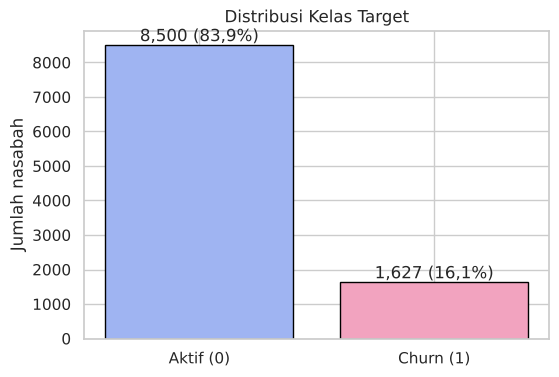

**Analisis.** Dari 10.127 nasabah, 8.500 (83,93%) masih aktif dan 1.627 (16,07%) churn. Perbandingannya sekitar 5,2 banding 1, jadi data **tidak seimbang**. Kalau model menebak semua nasabah aktif saja, akurasinya sudah 83,93% padahal tidak ada satu pun churn yang terdeteksi. Karena itu akurasi saja tidak cukup, dan **recall serta F1-score kelas churn** harus ikut dilihat. Ketimpangan ini juga ditangani dengan `class_weight='balanced'` pada model.

In [5]:
# 5. Cek ketidakseimbangan kelas (imbalance)
hitung = df["Churn"].value_counts().sort_index()
n_aktif_all, n_churn_all = int(hitung[0]), int(hitung[1])
n_all = n_aktif_all + n_churn_all
print(hitung)
print((hitung / n_all * 100).round(2))

fig, ax = plt.subplots(figsize=(6, 4))
batang = ax.bar(["Aktif (0)", "Churn (1)"], [n_aktif_all, n_churn_all], color=["#9fb4f2", "#f2a3bf"], edgecolor="black")
for b, v in zip(batang, [n_aktif_all, n_churn_all]):
    ax.text(b.get_x() + b.get_width() / 2, v + 120, f"{ribuan(v)} ({v/n_all*100:.1f}%)".replace(".", ","), ha="center")
ax.set_ylabel("Jumlah nasabah")
ax.set_title("Distribusi Kelas Target")
plt.savefig("static/img/01_imbalance.png", dpi=150, bbox_inches="tight")
plt.show()

rasio = n_aktif_all / n_churn_all
tulis(f"**Analisis.** Dari {ribuan(n_all)} nasabah, {ribuan(n_aktif_all)} ({fmt(n_aktif_all/n_all*100)}%) masih aktif dan "
      f"{ribuan(n_churn_all)} ({fmt(n_churn_all/n_all*100)}%) churn. Perbandingannya sekitar {fmt(rasio, 1)} banding 1, jadi data **tidak seimbang**. "
      f"Kalau model menebak semua nasabah aktif saja, akurasinya sudah {fmt(n_aktif_all/n_all*100)}% padahal tidak ada satu pun churn yang terdeteksi. "
      f"Karena itu akurasi saja tidak cukup, dan **recall serta F1-score kelas churn** harus ikut dilihat. "
      f"Ketimpangan ini juga ditangani dengan `class_weight='balanced'` pada model.")

### 3.2 Perbandingan nasabah aktif dan churn
Tabel ini memberi gambaran awal fitur mana yang berbeda antar kelas. Nanti hasilnya dibandingkan dengan feature importance dari model.

In [6]:
# 6. Rata-rata fitur numerik per kelas dan persen churn per kategori
kolom_num_awal = df.drop(columns=["Churn"]).select_dtypes(exclude="object").columns
rata = df.groupby("Churn")[kolom_num_awal].mean().T
rata.columns = ["Aktif", "Churn"]
rata["Selisih (%)"] = (rata["Churn"] - rata["Aktif"]) / rata["Aktif"] * 100
print("Rata-rata fitur numerik per kelas (diurutkan dari selisih paling negatif):")
display(rata.sort_values("Selisih (%)").round(3))

for k in ["Card_Category", "Income_Category", "Gender"]:
    t = df.groupby(k)["Churn"].agg(["count", "mean"])
    t["mean"] = (t["mean"] * 100).round(2)
    t.columns = ["Jumlah nasabah", "Persen churn"]
    print(f"\nPersen churn berdasarkan {k}:")
    display(t)

Rata-rata fitur numerik per kelas (diurutkan dari selisih paling negatif):


,Aktif,Churn,Selisih (%)
Total_Revolving_Bal,1256.604,672.823,-46.457
Avg_Utilization_Ratio,0.296,0.162,-45.186
Total_Trans_Ct,68.673,44.934,-34.568
Total_Trans_Amt,4654.656,3095.026,-33.507
Total_Ct_Chng_Q4_Q1,0.742,0.554,-25.329
Total_Relationship_Count,3.915,3.280,-16.220
Total_Amt_Chng_Q4_Q1,0.773,0.694,-10.127
Credit_Limit,8726.878,8136.039,-6.770
Avg_Open_To_Buy,7470.273,7463.216,-0.094
Months_on_book,35.881,36.178,0.830



Persen churn berdasarkan Card_Category:


,Jumlah nasabah,Persen churn
Card_Category,,
Blue,9436,16.10
Gold,116,18.10
Platinum,20,25.00
Silver,555,14.77



Persen churn berdasarkan Income_Category:

,Jumlah nasabah,Persen churn
Income_Category,,
$120K +,727,17.33
$40K - $60K,1790,15.14
$60K - $80K,1402,13.48
$80K - $120K,1535,15.77
Less than $40K,3561,17.19
Unknown,1112,16.82



Persen churn berdasarkan Gender:


,Jumlah nasabah,Persen churn
Gender,,
F,5358,17.36
M,4769,14.62


## 4. Pembagian data, encoding, dan bobot kelas
Data dibagi **80% latih dan 20% uji** dengan `stratify` supaya proporsi churn di kedua bagian sama. Kolom kategori diubah ke angka dengan **One-Hot Encoding**. Encoding dimasukkan ke dalam pipeline bersama model agar aturan yang sama dipakai saat prediksi di web.

In [7]:
# 7. Pisahkan fitur dan target
X = df.drop(columns=["Churn"])
y = df["Churn"]

kolom_kat = X.select_dtypes(include="object").columns.tolist()
kolom_num = X.select_dtypes(exclude="object").columns.tolist()
print("Kategori :", kolom_kat)
print("Numerik  :", kolom_num)

# 8. Split data 80% latih, 20% uji (stratify supaya proporsi churn sama)
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, stratify=y, random_state=RANDOM_STATE)


# 9. One-Hot Encoding untuk kolom kategori
def buat_prep():
    try:
        enc = OneHotEncoder(handle_unknown="ignore", sparse_output=False)
    except TypeError:  # scikit-learn versi lama
        enc = OneHotEncoder(handle_unknown="ignore", sparse=False)
    return ColumnTransformer(
        [("kat", enc, kolom_kat), ("num", "passthrough", kolom_num)],
        verbose_feature_names_out=False)


prep = buat_prep()
X_train_enc = prep.fit_transform(X_train)
X_test_enc = prep.transform(X_test)
n_fitur_enc = len(prep.get_feature_names_out())

n_tr_aktif, n_tr_churn = int((y_train == 0).sum()), int((y_train == 1).sum())
n_te_aktif, n_te_churn = int((y_test == 0).sum()), int((y_test == 1).sum())
print("Data latih :", X_train.shape, "| aktif", n_tr_aktif, "| churn", n_tr_churn)
print("Data uji   :", X_test.shape, "| aktif", n_te_aktif, "| churn", n_te_churn)
print("Fitur setelah encoding:", n_fitur_enc)

n_kat_enc = n_fitur_enc - len(kolom_num)
tulis(f"**Hasil pembagian.** Data latih {ribuan(len(X_train))} baris ({ribuan(n_tr_aktif)} aktif dan {ribuan(n_tr_churn)} churn), "
      f"data uji {ribuan(len(X_test))} baris ({ribuan(n_te_aktif)} aktif dan {ribuan(n_te_churn)} churn). "
      f"Proporsi churn sama di kedua bagian ({fmt(n_tr_churn/len(X_train)*100)}% dan {fmt(n_te_churn/len(X_test)*100)}%). "
      f"Setelah One-Hot Encoding, {len(kolom_kat)} kolom kategori menjadi {n_kat_enc} kolom biner, sehingga total fitur model menjadi "
      f"{n_fitur_enc} ({len(kolom_num)} numerik dan {n_kat_enc} hasil encoding). "
      f"Untuk tiap percabangan pohon, scikit-learn memilih sekitar akar kuadrat dari jumlah fitur, yaitu {int(np.sqrt(n_fitur_enc))} fitur acak.")

Kategori : ['Gender', 'Education_Level', 'Marital_Status', 'Income_Category', 'Card_Category']
Numerik  : ['Customer_Age', 'Dependent_count', 'Months_on_book', 'Total_Relationship_Count', 'Months_Inactive_12_mon', 'Contacts_Count_12_mon', 'Credit_Limit', 'Total_Revolving_Bal', 'Avg_Open_To_Buy', 'Total_Amt_Chng_Q4_Q1', 'Total_Trans_Amt', 'Total_Trans_Ct', 'Total_Ct_Chng_Q4_Q1', 'Avg_Utilization_Ratio']
Data latih : (8101, 19) | aktif 6799 | churn 1302
Data uji   : (2026, 19) | aktif 1701 | churn 325
Fitur setelah encoding: 37


**Hasil pembagian.** Data latih 8.101 baris (6.799 aktif dan 1.302 churn), data uji 2.026 baris (1.701 aktif dan 325 churn). Proporsi churn sama di kedua bagian (16,07% dan 16,04%). Setelah One-Hot Encoding, 5 kolom kategori menjadi 23 kolom biner, sehingga total fitur model menjadi 37 (14 numerik dan 23 hasil encoding). Untuk tiap percabangan pohon, scikit-learn memilih sekitar akar kuadrat dari jumlah fitur, yaitu 6 fitur acak.

In [8]:
# 10. Hitung manual bobot kelas (class_weight = balanced)
n_total = len(y_train)
w_aktif = n_total / (2 * n_tr_aktif)
w_churn = n_total / (2 * n_tr_churn)
w_sk = compute_class_weight("balanced", classes=np.array([0, 1]), y=y_train)

print(f"Bobot aktif manual = {n_total} / (2 x {n_tr_aktif}) = {w_aktif:.4f} | scikit-learn: {w_sk[0]:.4f}")
print(f"Bobot churn manual = {n_total} / (2 x {n_tr_churn}) = {w_churn:.4f} | scikit-learn: {w_sk[1]:.4f}")
assert abs(w_aktif - w_sk[0]) < 1e-9 and abs(w_churn - w_sk[1]) < 1e-9

tulis(f"**Bobot kelas.** Rumusnya `w = n / (K x n_kelas)` dengan K = 2 kelas. Bobot kelas aktif {fmt(w_aktif, 4)} dan bobot kelas churn {fmt(w_churn, 4)}. "
      f"Artinya satu kesalahan pada nasabah churn dihitung sekitar {fmt(w_churn/w_aktif, 1)} kali lebih berat daripada kesalahan pada nasabah aktif, "
      f"sehingga model tidak hanya berfokus pada kelas mayoritas. Hitungan manual cocok dengan hasil scikit-learn.")

Bobot aktif manual = 8101 / (2 x 6799) = 0.5957 | scikit-learn: 0.5957
Bobot churn manual = 8101 / (2 x 1302) = 3.1110 | scikit-learn: 3.1110


**Bobot kelas.** Rumusnya `w = n / (K x n_kelas)` dengan K = 2 kelas. Bobot kelas aktif 0,5957 dan bobot kelas churn 3,1110. Artinya satu kesalahan pada nasabah churn dihitung sekitar 5,2 kali lebih berat daripada kesalahan pada nasabah aktif, sehingga model tidak hanya berfokus pada kelas mayoritas. Hitungan manual cocok dengan hasil scikit-learn.

## 5. Skenario A: pengaruh jumlah pohon (`n_estimators`)
Model dilatih dengan jumlah pohon 10, 50, 100, 200, dan 500, pengaturan lain tetap. Dicatat akurasi training, akurasi testing, dan F1-score kelas churn.

,n_estimators,acc_train,acc_test,f1_churn
0,10,0.9972,0.9418,0.8127
1,50,0.9986,0.9566,0.8621
2,100,0.9988,0.9541,0.8554
3,200,0.9990,0.9526,0.8500
4,500,0.9993,0.9521,0.8496


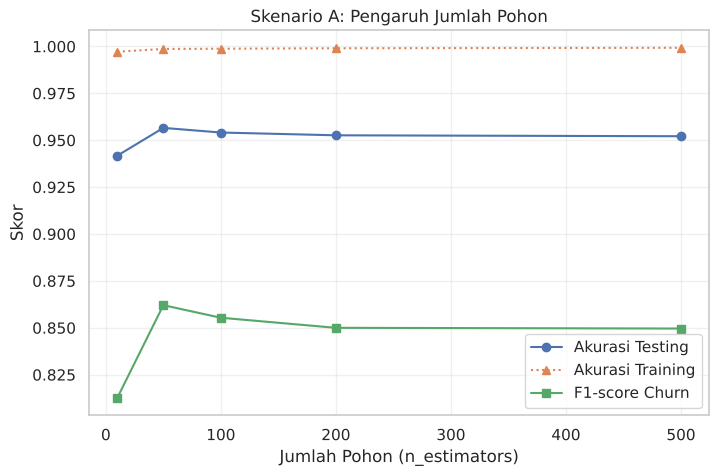

n_estimators terbaik: 50


In [9]:
# 11. Skenario A: pengaruh jumlah pohon (n_estimators)
daftar_n = [10, 50, 100, 200, 500]
hasil_a = []

for n in daftar_n:
    rf = RandomForestClassifier(n_estimators=n, class_weight="balanced",
                                random_state=RANDOM_STATE, n_jobs=-1)
    rf.fit(X_train_enc, y_train)
    pred = rf.predict(X_test_enc)
    hasil_a.append({
        "n_estimators": n,
        "acc_train": accuracy_score(y_train, rf.predict(X_train_enc)),
        "acc_test": accuracy_score(y_test, pred),
        "f1_churn": f1_score(y_test, pred),
    })

df_a = pd.DataFrame(hasil_a)
display(df_a.round(4))

# 12. Grafik garis Skenario A
plt.figure(figsize=(8, 5))
plt.plot(df_a["n_estimators"], df_a["acc_test"], marker="o", label="Akurasi Testing")
plt.plot(df_a["n_estimators"], df_a["acc_train"], marker="^", linestyle=":", label="Akurasi Training")
plt.plot(df_a["n_estimators"], df_a["f1_churn"], marker="s", label="F1-score Churn")
plt.xlabel("Jumlah Pohon (n_estimators)")
plt.ylabel("Skor")
plt.title("Skenario A: Pengaruh Jumlah Pohon")
plt.grid(alpha=0.3)
plt.legend()
plt.savefig("static/img/02_skenario_a.png", dpi=150, bbox_inches="tight")
plt.show()

# 13. Pilih n_estimators terbaik (akurasi testing tertinggi)
best_n = int(df_a.loc[df_a["acc_test"].idxmax(), "n_estimators"])
print("n_estimators terbaik:", best_n)

In [10]:
# 14. Analisis otomatis Skenario A
ns = df_a["n_estimators"].tolist()
te = df_a["acc_test"].tolist()
tr = df_a["acc_train"].tolist()
f1 = df_a["f1_churn"].tolist()
ib = int(np.argmax(te))

teks = "**Analisis Skenario A.** "
if ib > 0:
    teks += (f"Dari {ns[0]} ke {ns[ib]} pohon, akurasi testing naik {fmt((te[ib]-te[0])*100)} poin "
             f"(dari {fmt(te[0]*100)}% ke {fmt(te[ib]*100)}%) dan F1-score churn naik dari {fmt(f1[0], 4)} ke {fmt(f1[ib], 4)}. ")
else:
    teks += f"Akurasi testing tertinggi sudah ada pada jumlah pohon paling sedikit ({ns[0]} pohon, {fmt(te[0]*100)}%). "

if ib < len(ns) - 1:
    turun = round(te[ib] * 100, 2) - round(te[-1] * 100, 2)
    sifat = "turun tipis" if turun < 1.0 else "turun cukup terlihat"
    teks += (f"Setelah itu akurasi tidak naik lagi dan {sifat} menjadi {fmt(te[-1]*100)}% pada {ns[-1]} pohon "
             f"(turun {fmt(turun)} poin dari titik tertinggi). ")
    if turun < 0.5:
        teks += "Selisih sekecil ini masih bisa dianggap variasi acak. "
    if tr[-1] > tr[ib]:
        teks += (f"Akurasi training justru terus naik ({fmt(tr[ib]*100)}% menjadi {fmt(tr[-1]*100)}%) tetapi akurasi testing tidak ikut naik, "
                 f"jadi pohon tambahan hanya menambah waktu komputasi dan memori. ")
    teks += f"**Kesimpulan:** menambah pohon terus-menerus tidak meningkatkan akurasi secara signifikan pada dataset ini. Dipakai **{ns[ib]} pohon** untuk skenario B."
else:
    teks += (f"Akurasi masih naik sampai jumlah pohon terbesar yang dicoba ({ns[-1]} pohon). "
             f"**Kesimpulan:** dipakai **{ns[ib]} pohon** untuk skenario B, dan jumlah pohon yang lebih besar masih layak dicoba.")
tulis(teks)

**Analisis Skenario A.** Dari 10 ke 50 pohon, akurasi testing naik 1,48 poin (dari 94,18% ke 95,66%) dan F1-score churn naik dari 0,8127 ke 0,8621. Setelah itu akurasi tidak naik lagi dan turun tipis menjadi 95,21% pada 500 pohon (turun 0,45 poin dari titik tertinggi). Selisih sekecil ini masih bisa dianggap variasi acak. Akurasi training justru terus naik (99,86% menjadi 99,93%) tetapi akurasi testing tidak ikut naik, jadi pohon tambahan hanya menambah waktu komputasi dan memori. **Kesimpulan:** menambah pohon terus-menerus tidak meningkatkan akurasi secara signifikan pada dataset ini. Dipakai **50 pohon** untuk skenario B.

## 6. Skenario B: pengaruh kedalaman pohon (`max_depth`)
Dengan jumlah pohon terbaik dari skenario A, kedalaman pohon divariasikan: tanpa batas (None), 3, 5, 10, dan 20. Akurasi training dan testing dibandingkan untuk mencari titik mulai overfitting.

,max_depth,acc_train,acc_test,selisih
0,Unlimited,0.9986,0.9566,0.0421
1,3,0.8369,0.8391,-0.0022
2,5,0.8983,0.8949,0.0034
3,10,0.9774,0.9452,0.0322
4,20,0.9981,0.9551,0.0431


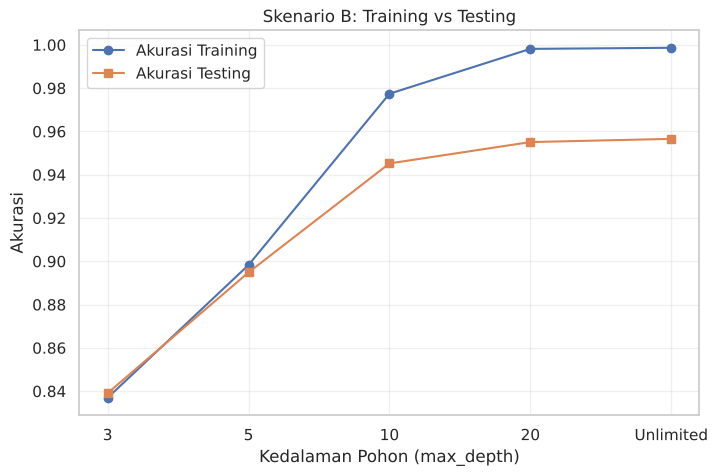

max_depth terbaik: Unlimited


In [11]:
# 15. Skenario B: pengaruh kedalaman pohon (max_depth)
daftar_depth = [None, 3, 5, 10, 20]
hasil_b = []

for d in daftar_depth:
    rf = RandomForestClassifier(n_estimators=best_n, max_depth=d,
                                class_weight="balanced",
                                random_state=RANDOM_STATE, n_jobs=-1)
    rf.fit(X_train_enc, y_train)
    tr_acc = accuracy_score(y_train, rf.predict(X_train_enc))
    te_acc = accuracy_score(y_test, rf.predict(X_test_enc))
    hasil_b.append({
        "max_depth": "Unlimited" if d is None else str(d),
        "acc_train": tr_acc,
        "acc_test": te_acc,
        "selisih": tr_acc - te_acc,
    })

df_b = pd.DataFrame(hasil_b)
display(df_b.round(4))

# 16. Grafik garis Training vs Testing (diurutkan 3, 5, 10, 20, Unlimited)
df_b_plot = df_b.iloc[[1, 2, 3, 4, 0]]
plt.figure(figsize=(8, 5))
plt.plot(df_b_plot["max_depth"], df_b_plot["acc_train"], marker="o", label="Akurasi Training")
plt.plot(df_b_plot["max_depth"], df_b_plot["acc_test"], marker="s", label="Akurasi Testing")
plt.xlabel("Kedalaman Pohon (max_depth)")
plt.ylabel("Akurasi")
plt.title("Skenario B: Training vs Testing")
plt.grid(alpha=0.3)
plt.legend()
plt.savefig("static/img/03_skenario_b.png", dpi=150, bbox_inches="tight")
plt.show()

# 17. Pilih max_depth terbaik (akurasi testing tertinggi, lalu selisih train-test terkecil)
urut = df_b.assign(acc_r=df_b["acc_test"].round(3)).sort_values(
    ["acc_r", "selisih"], ascending=[False, True])
idx_best = urut.index[0]
best_depth = daftar_depth[idx_best]
best_depth_label = df_b.loc[idx_best, "max_depth"]
print("max_depth terbaik:", best_depth_label)

In [12]:
# 18. Analisis otomatis Skenario B
rows = df_b.iloc[[1, 2, 3, 4, 0]].reset_index(drop=True)
nama = lambda r: "tanpa batas" if r["max_depth"] == "Unlimited" else r["max_depth"]
teks = "**Analisis Skenario B.** "

under = rows[(rows["acc_train"] < 0.92) & (rows["selisih"].abs() < 0.01)]
if len(under):
    bagian = " dan ".join(f"{nama(r)} (training {fmt(r['acc_train']*100)}%, testing {fmt(r['acc_test']*100)}%)" for _, r in under.iterrows())
    teks += (f"Pada max_depth {bagian}, akurasi training dan testing sama-sama rendah dan hampir sama besar. "
             f"Ini tanda model terlalu sederhana (**underfitting**). ")

lebar = rows[rows["selisih"] > 0.02]
if len(lebar):
    r0 = lebar.iloc[0]
    rmax = rows.loc[rows["selisih"].idxmax()]
    teks += (f"Selisih akurasi training dan testing mulai melebar dari max_depth **{nama(r0)}** "
             f"(training {fmt(r0['acc_train']*100)}%, testing {fmt(r0['acc_test']*100)}%, selisih {fmt(r0['selisih']*100)} poin), "
             f"dan paling besar pada max_depth {nama(rmax)} ({fmt(rmax['selisih']*100)} poin). "
             f"Jadi kedalaman {nama(r0)} adalah titik tempat akurasi training mulai meninggalkan testing. ")
else:
    teks += "Selisih akurasi training dan testing tetap kecil di semua kedalaman, jadi belum terlihat overfitting yang jelas. "

rb = df_b.loc[idx_best]
tertinggi = rb["acc_test"] >= rows["acc_test"].max() - 1e-12
if tertinggi:
    teks += (f"Meski selisih training dan testing pada model terbaik sekitar {fmt(rb['selisih']*100)} poin, "
             f"akurasi testing di kedalaman ini tidak turun, justru paling tinggi ({fmt(rb['acc_test']*100)}%), "
             f"sehingga selisih tersebut masih dapat diterima. ")
else:
    teks += (f"Kedalaman {nama(rb)} dipilih karena akurasi testingnya tertinggi (dibulatkan tiga desimal) dengan selisih training-testing terkecil "
             f"({fmt(rb['selisih']*100)} poin). ")

alt = rows[(rows["max_depth"] != best_depth_label) & (rows["max_depth"] != "Unlimited") &
           (rows["acc_test"] >= rb["acc_test"] - 0.003)]
if len(alt):
    ra = alt.loc[alt["acc_test"].idxmax()]
    teks += (f"Sebagai alternatif yang lebih ringan, max_depth {ra['max_depth']} hanya terpaut "
             f"{fmt((rb['acc_test']-ra['acc_test'])*100)} poin ({fmt(ra['acc_test']*100)}%). ")

teks += f"**Konfigurasi terbaik:** n_estimators = {best_n} dan max_depth = {nama(rb)}."
tulis(teks)

**Analisis Skenario B.** Pada max_depth 3 (training 83,69%, testing 83,91%) dan 5 (training 89,83%, testing 89,49%), akurasi training dan testing sama-sama rendah dan hampir sama besar. Ini tanda model terlalu sederhana (**underfitting**). Selisih akurasi training dan testing mulai melebar dari max_depth **10** (training 97,74%, testing 94,52%, selisih 3,22 poin), dan paling besar pada max_depth 20 (4,31 poin). Jadi kedalaman 10 adalah titik tempat akurasi training mulai meninggalkan testing. Meski selisih training dan testing pada model terbaik sekitar 4,21 poin, akurasi testing di kedalaman ini tidak turun, justru paling tinggi (95,66%), sehingga selisih tersebut masih dapat diterima. Sebagai alternatif yang lebih ringan, max_depth 20 hanya terpaut 0,15 poin (95,51%). **Konfigurasi terbaik:** n_estimators = 50 dan max_depth = tanpa batas.

## 7. Model terbaik dan evaluasi akhir
Model dilatih ulang dengan konfigurasi terbaik dalam satu **pipeline** (encoding + Random Forest), lalu dievaluasi pada data uji.

In [13]:
# 19. Model terbaik (pipeline: encoding + Random Forest)
model = Pipeline([
    ("prep", buat_prep()),
    ("rf", RandomForestClassifier(n_estimators=best_n, max_depth=best_depth,
                                  class_weight="balanced",
                                  random_state=RANDOM_STATE, n_jobs=-1)),
])
model.fit(X_train, y_train)

# 20. Evaluasi model terbaik
y_pred = model.predict(X_test)
y_proba = model.predict_proba(X_test)[:, 1]
acc = accuracy_score(y_test, y_pred)
auc = roc_auc_score(y_test, y_proba)
acc_train_final = accuracy_score(y_train, model.predict(X_train))

print("Akurasi Training:", round(acc_train_final, 4))
print("Akurasi Testing :", round(acc, 4))
print("ROC AUC         :", round(auc, 4))
print("\nLaporan Klasifikasi:\n",
      classification_report(y_test, y_pred, target_names=["Aktif", "Churn"]))

Akurasi Training: 0.9986
Akurasi Testing : 0.9566
ROC AUC         : 0.9831

Laporan Klasifikasi:
               precision    recall  f1-score   support

       Aktif       0.97      0.98      0.97      1701
       Churn       0.88      0.85      0.86       325

    accuracy                           0.96      2026
   macro avg       0.92      0.91      0.92      2026
weighted avg       0.96      0.96      0.96      2026



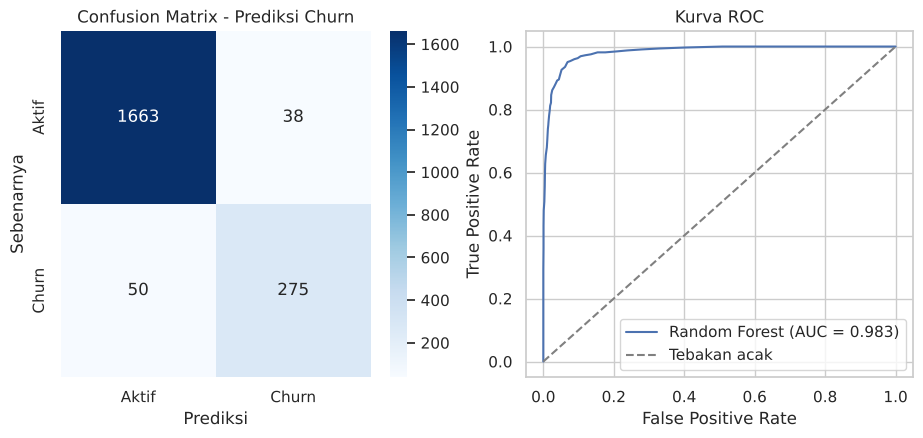

In [14]:
# 21. Confusion matrix dan kurva ROC
cm = confusion_matrix(y_test, y_pred)
fig, ax = plt.subplots(1, 2, figsize=(11, 4.5))

sns.heatmap(cm, annot=True, fmt="d", cmap="Blues", ax=ax[0],
            xticklabels=["Aktif", "Churn"], yticklabels=["Aktif", "Churn"])
ax[0].set_xlabel("Prediksi")
ax[0].set_ylabel("Sebenarnya")
ax[0].set_title("Confusion Matrix - Prediksi Churn")

fpr, tpr, _ = roc_curve(y_test, y_proba)
ax[1].plot(fpr, tpr, label=f"Random Forest (AUC = {auc:.3f})")
ax[1].plot([0, 1], [0, 1], linestyle="--", color="gray", label="Tebakan acak")
ax[1].set_xlabel("False Positive Rate")
ax[1].set_ylabel("True Positive Rate")
ax[1].set_title("Kurva ROC")
ax[1].legend(loc="lower right")

plt.savefig("static/img/04_confusion_matrix.png", dpi=150, bbox_inches="tight")
plt.show()

In [15]:
# 22. Hitung metrik secara manual dari confusion matrix
(tn, fp), (fn, tp) = cm
acc_m = (tp + tn) / (tp + tn + fp + fn)
prec_c = tp / (tp + fp)
rec_c = tp / (tp + fn)
f1_c = 2 * prec_c * rec_c / (prec_c + rec_c)
prec_a = tn / (tn + fn)
rec_a = tn / (tn + fp)
f1_a = 2 * prec_a * rec_a / (prec_a + rec_a)

print(f"TN = {tn}, FP = {fp}, FN = {fn}, TP = {tp}")
print(f"Akurasi         = ({tp} + {tn}) / {tp+tn+fp+fn} = {acc_m:.4f}")
print(f"Precision churn = {tp} / ({tp} + {fp}) = {prec_c:.4f}")
print(f"Recall churn    = {tp} / ({tp} + {fn}) = {rec_c:.4f}")
print(f"F1 churn        = 2 x {prec_c:.4f} x {rec_c:.4f} / ({prec_c:.4f} + {rec_c:.4f}) = {f1_c:.4f}")
print(f"F1 aktif        = {f1_a:.4f}")
print(f"Macro F1        = ({f1_a:.4f} + {f1_c:.4f}) / 2 = {(f1_a + f1_c) / 2:.4f}")

# cocokkan dengan scikit-learn
lap = classification_report(y_test, y_pred, target_names=["Aktif", "Churn"], output_dict=True)
assert abs(acc_m - acc) < 1e-9 and abs(f1_c - lap["Churn"]["f1-score"]) < 1e-9
print("\nHitungan manual cocok dengan scikit-learn.")

tulis(f"**Analisis evaluasi.** Model terbaik mencapai akurasi testing {fmt(acc*100)}% (training {fmt(acc_train_final*100)}%) dan ROC AUC {fmt(auc, 3)}. "
      f"Dari {tp+fn} nasabah churn di data uji, **{tp} berhasil ditangkap** (recall {fmt(rec_c*100, 1)}%), dan dari {tp+fp} nasabah yang ditandai berisiko, "
      f"{tp} memang churn (precision {fmt(prec_c*100, 1)}%). F1-score churn {fmt(f1_c, 3)}. "
      f"Ada **{fn} nasabah churn yang lolos** dan **{fp} nasabah aktif yang salah ditandai**. "
      f"Bagi bank, {fp} salah tandai hanya berakibat promo diberikan ke nasabah yang sebenarnya bertahan, sedangkan {fn} yang lolos adalah nasabah yang hilang tanpa sempat didekati. "
      f"Hasil ini jauh di atas akurasi tebakan kelas mayoritas ({fmt(n_aktif_all/n_all*100)}%), dan hitungan manual di atas cocok dengan keluaran scikit-learn.")

TN = 1663, FP = 38, FN = 50, TP = 275
Akurasi         = (275 + 1663) / 2026 = 0.9566
Precision churn = 275 / (275 + 38) = 0.8786
Recall churn    = 275 / (275 + 50) = 0.8462
F1 churn        = 2 x 0.8786 x 0.8462 / (0.8786 + 0.8462) = 0.8621
F1 aktif        = 0.9742
Macro F1        = (0.9742 + 0.8621) / 2 = 0.9181

Hitungan manual cocok dengan scikit-learn.


**Analisis evaluasi.** Model terbaik mencapai akurasi testing 95,66% (training 99,86%) dan ROC AUC 0,983. Dari 325 nasabah churn di data uji, **275 berhasil ditangkap** (recall 84,6%), dan dari 313 nasabah yang ditandai berisiko, 275 memang churn (precision 87,9%). F1-score churn 0,862. Ada **50 nasabah churn yang lolos** dan **38 nasabah aktif yang salah ditandai**. Bagi bank, 38 salah tandai hanya berakibat promo diberikan ke nasabah yang sebenarnya bertahan, sedangkan 50 yang lolos adalah nasabah yang hilang tanpa sempat didekati. Hasil ini jauh di atas akurasi tebakan kelas mayoritas (83,93%), dan hitungan manual di atas cocok dengan keluaran scikit-learn.

## 8. Contoh hitungan manual: Gini dan voting
Supaya cara kerja Random Forest lebih jelas, berikut dua contoh yang dihitung dari data sendiri: (1) satu pemisahan pohon memakai **Gini impurity**, dan (2) **voting** banyak pohon pada satu nasabah.

In [16]:
# 23. Gini manual untuk satu pemisahan pada fitur Total_Trans_Ct (data latih, tanpa bobot kelas)
def gini(a, b):
    t = a + b
    return 1 - (a / t) ** 2 - (b / t) ** 2 if t else 0.0


kol = X_train["Total_Trans_Ct"].values
yy = y_train.values
g_akar = gini(n_tr_aktif, n_tr_churn)

terbaik = None
for th in np.unique(kol):
    L = kol <= th
    nl, nr = int(L.sum()), int((~L).sum())
    if nl == 0 or nr == 0:
        continue
    gl = gini(int((yy[L] == 0).sum()), int((yy[L] == 1).sum()))
    gr = gini(int((yy[~L] == 0).sum()), int((yy[~L] == 1).sum()))
    w = (nl * gl + nr * gr) / len(yy)
    if terbaik is None or w < terbaik["w"]:
        terbaik = dict(th=float(th), nl=nl, nr=nr, gl=gl, gr=gr, w=w,
                       l0=int((yy[L] == 0).sum()), l1=int((yy[L] == 1).sum()),
                       r0=int((yy[~L] == 0).sum()), r1=int((yy[~L] == 1).sum()))
gain = g_akar - terbaik["w"]
T = terbaik

tabel_gini = pd.DataFrame({
    "Node": ["Akar", f"Kiri (<= {int(T['th'])})", f"Kanan (> {int(T['th'])})"],
    "Aktif": [n_tr_aktif, T["l0"], T["r0"]],
    "Churn": [n_tr_churn, T["l1"], T["r1"]],
    "Total": [len(yy), T["nl"], T["nr"]],
    "Gini": [round(g_akar, 4), round(T["gl"], 4), round(T["gr"], 4)],
})
display(tabel_gini)

print(f"Gini akar       = 1 - ({n_tr_aktif}/{len(yy)})^2 - ({n_tr_churn}/{len(yy)})^2 = {g_akar:.4f}")
print(f"Gini kiri       = 1 - ({T['l0']}/{T['nl']})^2 - ({T['l1']}/{T['nl']})^2 = {T['gl']:.4f}")
print(f"Gini kanan      = 1 - ({T['r0']}/{T['nr']})^2 - ({T['r1']}/{T['nr']})^2 = {T['gr']:.4f}")
print(f"Gini pemisahan  = ({T['nl']} x {T['gl']:.4f} + {T['nr']} x {T['gr']:.4f}) / {len(yy)} = {T['w']:.4f}")
print(f"Penurunan Gini  = {g_akar:.4f} - {T['w']:.4f} = {gain:.4f}")

tulis(f"**Analisis.** Batas terbaik pada `Total_Trans_Ct` adalah **{int(T['th'])} transaksi**. Di sisi kiri (kurang dari atau sama dengan {int(T['th'])}) "
      f"{fmt(T['l1']/T['nl']*100, 1)}% nasabahnya churn, sedangkan di sisi kanan hanya {fmt(T['r1']/T['nr']*100, 1)}%. "
      f"Karena kedua sisi lebih murni daripada node akar, Gini turun sebesar {fmt(gain, 4)}. "
      f"Contoh ini disederhanakan: tanpa bobot kelas, hanya satu fitur, dan batas dicari dengan mencoba semua nilai. "
      f"Di dalam hutan sungguhan, tiap percabangan hanya memilih dari {int(np.sqrt(n_fitur_enc))} fitur acak, sehingga batas yang dipakai tiap pohon bisa berbeda.")

,Node,Aktif,Churn,Total,Gini
0,Akar,6799,1302,8101,0.2698
1,Kiri (<= 54),1755,1054,2809,0.4689
2,Kanan (> 54),5044,248,5292,0.0893


Gini akar       = 1 - (6799/8101)^2 - (1302/8101)^2 = 0.2698
Gini kiri       = 1 - (1755/2809)^2 - (1054/2809)^2 = 0.4689
Gini kanan      = 1 - (5044/5292)^2 - (248/5292)^2 = 0.0893
Gini pemisahan  = (2809 x 0.4689 + 5292 x 0.0893) / 8101 = 0.2209
Penurunan Gini  = 0.2698 - 0.2209 = 0.0488


**Analisis.** Batas terbaik pada `Total_Trans_Ct` adalah **54 transaksi**. Di sisi kiri (kurang dari atau sama dengan 54) 37,5% nasabahnya churn, sedangkan di sisi kanan hanya 4,7%. Karena kedua sisi lebih murni daripada node akar, Gini turun sebesar 0,0488. Contoh ini disederhanakan: tanpa bobot kelas, hanya satu fitur, dan batas dicari dengan mencoba semua nilai. Di dalam hutan sungguhan, tiap percabangan hanya memilih dari 6 fitur acak, sehingga batas yang dipakai tiap pohon bisa berbeda.

In [17]:
# 24. Contoh voting banyak pohon pada nasabah uji
pre = model.named_steps["prep"]
rf_akhir = model.named_steps["rf"]

kandidat = np.where((y_proba > 0.45) & (y_proba < 0.60))[0]
i_tengah = int(kandidat[0]) if len(kandidat) else int(np.argsort(np.abs(y_proba - 0.5))[0])
i_tinggi = int(np.argmax(y_proba))


def suara(i):
    xi = pre.transform(X_test.iloc[[i]])
    vote = np.array([t.predict(xi)[0] for t in rf_akhir.estimators_])
    return int((vote == 1).sum()), len(vote)


v1, jml = suara(i_tengah)
v2, _ = suara(i_tinggi)
label1 = "churn" if y_test.iloc[i_tengah] == 1 else "aktif"
pred1 = "churn" if y_proba[i_tengah] >= 0.5 else "aktif"

print(f"Nasabah uji #{i_tengah}: {v1} dari {jml} pohon memilih churn -> skor {v1}/{jml} = {v1/jml:.2f}")
print(f"Nasabah uji #{i_tinggi}: {v2} dari {jml} pohon memilih churn -> skor {v2}/{jml} = {v2/jml:.2f}")

tulis(f"**Analisis voting.** Pada nasabah dengan skor di tengah, **{v1} dari {jml} pohon** memilih churn, jadi skornya {v1}/{jml} = {fmt(v1/jml)}. "
      f"Skor ini {'di bawah' if v1/jml < 0.5 else 'di atas atau sama dengan'} 0,5, sehingga diprediksi **{pred1}**, dan label aslinya adalah **{label1}** "
      f"({'prediksi benar' if pred1 == label1 else 'prediksi salah'}). "
      f"Sebagai pembanding, nasabah dengan skor tertinggi mendapat {v2} suara churn dari {jml} pohon (skor {fmt(v2/jml)}). "
      f"Di scikit-learn, voting dilakukan dengan merata-ratakan probabilitas semua pohon, dan karena daun pohon penuh biasanya murni, hasilnya sama dengan proporsi suara.")

Nasabah uji #35: 24 dari 50 pohon memilih churn -> skor 24/50 = 0.48
Nasabah uji #191: 50 dari 50 pohon memilih churn -> skor 50/50 = 1.00


**Analisis voting.** Pada nasabah dengan skor di tengah, **24 dari 50 pohon** memilih churn, jadi skornya 24/50 = 0,48. Skor ini di bawah 0,5, sehingga diprediksi **aktif**, dan label aslinya adalah **aktif** (prediksi benar). Sebagai pembanding, nasabah dengan skor tertinggi mendapat 50 suara churn dari 50 pohon (skor 1,00). Di scikit-learn, voting dilakukan dengan merata-ratakan probabilitas semua pohon, dan karena daun pohon penuh biasanya murni, hasilnya sama dengan proporsi suara.

## 9. Feature importance dan insight bisnis
Dari model terbaik diambil `feature_importances_`, yaitu rata-rata penurunan Gini tiap fitur di seluruh pohon yang dinormalkan sehingga jumlahnya 1. Hasilnya dibandingkan dengan rata-rata fitur pada kelas aktif dan churn.

,Feature,Importance
0,Total_Trans_Amt,0.2072
1,Total_Trans_Ct,0.2014
2,Total_Revolving_Bal,0.1002
3,Total_Ct_Chng_Q4_Q1,0.0898
4,Avg_Utilization_Ratio,0.0651
5,Total_Amt_Chng_Q4_Q1,0.0575
6,Total_Relationship_Count,0.0487
7,Months_Inactive_12_mon,0.0332
8,Avg_Open_To_Buy,0.0284
9,Credit_Limit,0.0280


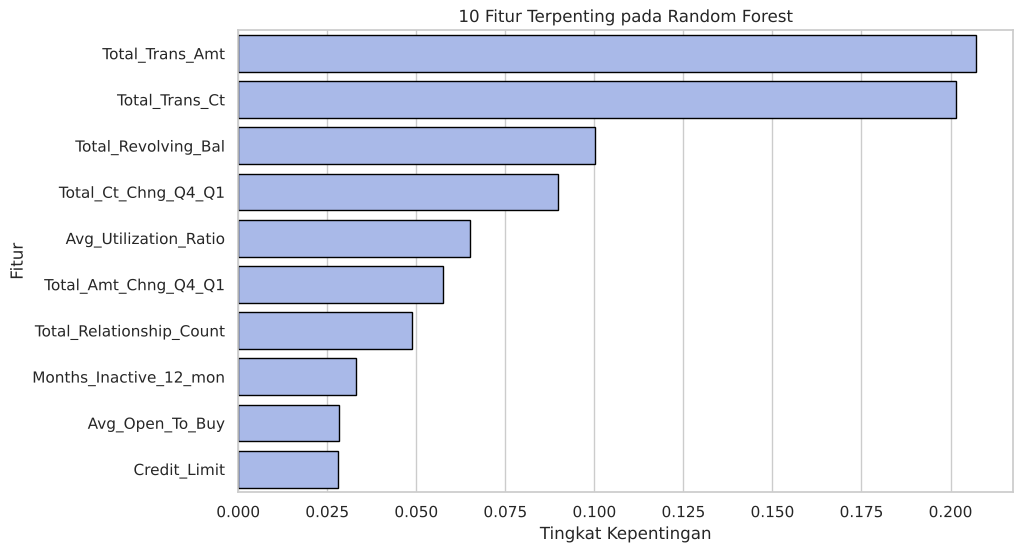

In [18]:
# 25. Feature importance 10 fitur teratas
nama_fitur = model.named_steps["prep"].get_feature_names_out()
penting = model.named_steps["rf"].feature_importances_
imp = pd.DataFrame({"Feature": nama_fitur, "Importance": penting}).sort_values("Importance", ascending=False)
top10 = imp.head(10)
display(top10.round(4).reset_index(drop=True))

plt.figure(figsize=(10, 6))
sns.barplot(x=top10["Importance"], y=top10["Feature"], color="#9fb4f2", edgecolor="black")
plt.xlabel("Tingkat Kepentingan")
plt.ylabel("Fitur")
plt.title("10 Fitur Terpenting pada Random Forest")
plt.savefig("static/img/05_feature_importance.png", dpi=150, bbox_inches="tight")
plt.show()

In [19]:
# 26. Interpretasi otomatis feature importance dan insight bisnis
arti = {
    "Total_Trans_Amt": "total nominal transaksi dalam 12 bulan",
    "Total_Trans_Ct": "jumlah transaksi dalam 12 bulan",
    "Total_Revolving_Bal": "saldo revolving (tagihan yang belum dilunasi)",
    "Total_Ct_Chng_Q4_Q1": "perubahan jumlah transaksi kuartal 4 dibanding kuartal 1",
    "Total_Amt_Chng_Q4_Q1": "perubahan nominal transaksi kuartal 4 dibanding kuartal 1",
    "Avg_Utilization_Ratio": "rasio pemakaian limit kartu",
    "Total_Relationship_Count": "jumlah produk bank yang dipakai nasabah",
    "Months_Inactive_12_mon": "jumlah bulan tanpa aktivitas dalam 12 bulan",
    "Contacts_Count_12_mon": "jumlah kontak nasabah ke bank dalam 12 bulan",
    "Credit_Limit": "limit kredit",
    "Avg_Open_To_Buy": "sisa limit yang masih bisa dipakai",
    "Customer_Age": "usia nasabah",
    "Months_on_book": "lama menjadi nasabah (bulan)",
    "Dependent_count": "jumlah tanggungan",
}

top3 = float(top10["Importance"].head(3).sum())
t3 = [f"`{f}`" for f in top10["Feature"].head(3)]
nama_top3 = ", ".join(t3[:2]) + " dan " + t3[2]
teks = (f"**Interpretasi.** Tiga fitur teratas adalah {nama_top3}, dan bersama-sama menyumbang {fmt(top3*100, 1)}% dari seluruh nilai importance. "
        f"Berikut perbandingan rata-rata fitur teratas pada kedua kelas (data lengkap):\n\n")
teks += "| Fitur | Arti | Rata-rata aktif | Rata-rata churn | Arah |\n|---|---|---|---|---|\n"

for f in top10["Feature"].head(6):
    if f in kolom_num:
        a, c = rata.loc[f, "Aktif"], rata.loc[f, "Churn"]
        arah = "churn lebih rendah" if c < a else "churn lebih tinggi"
        d = 3 if abs(a) < 10 else 1
        teks += f"| `{f}` | {arti.get(f, '-')} | {fmt(a, d)} | {fmt(c, d)} | {arah} |\n"

rendah = [f for f in top10["Feature"].head(6) if f in kolom_num and rata.loc[f, "Churn"] < rata.loc[f, "Aktif"]]
teks += (f"\n**Makna bisnis.** Nasabah churn punya nilai lebih rendah pada {len(rendah)} dari 6 fitur teratas yang berbentuk angka, yaitu "
         f"{', '.join('`'+f+'`' for f in rendah)}. "
         f"Pola ini masuk akal: nasabah yang mulai meninggalkan kartunya biasanya makin jarang belanja, saldo yang berputar mengecil, dan limit makin sedikit dipakai. "
         f"Bank bisa memakai sinyal ini sebagai peringatan dini, misalnya memantau nasabah yang jumlah transaksinya di kuartal 4 jauh di bawah kuartal 1, "
         f"lalu menawarkan cashback atau program loyalitas. ")
if "Total_Relationship_Count" in kolom_num:
    a, c = rata.loc["Total_Relationship_Count", "Aktif"], rata.loc["Total_Relationship_Count", "Churn"]
    if c < a:
        teks += (f"Nasabah yang memakai lebih banyak produk bank juga cenderung bertahan (rata-rata {fmt(a)} produk pada nasabah aktif dan {fmt(c)} pada nasabah churn), "
                 f"jadi menawarkan produk tambahan bisa membantu retensi. ")
teks += ("\n\n**Catatan.** `Total_Trans_Amt` dan `Total_Trans_Ct` berkaitan erat sehingga nilai importance-nya terbagi di antara keduanya, "
         "begitu juga `Credit_Limit` dan `Avg_Open_To_Buy`. Importance hanya menunjukkan fitur yang dipakai model, bukan penyebab nasabah berhenti.")
tulis(teks)

**Interpretasi.** Tiga fitur teratas adalah `Total_Trans_Amt`, `Total_Trans_Ct` dan `Total_Revolving_Bal`, dan bersama-sama menyumbang 50,9% dari seluruh nilai importance. Berikut perbandingan rata-rata fitur teratas pada kedua kelas (data lengkap):

| Fitur | Arti | Rata-rata aktif | Rata-rata churn | Arah |
|---|---|---|---|---|
| `Total_Trans_Amt` | total nominal transaksi dalam 12 bulan | 4654,7 | 3095,0 | churn lebih rendah |
| `Total_Trans_Ct` | jumlah transaksi dalam 12 bulan | 68,7 | 44,9 | churn lebih rendah |
| `Total_Revolving_Bal` | saldo revolving (tagihan yang belum dilunasi) | 1256,6 | 672,8 | churn lebih rendah |
| `Total_Ct_Chng_Q4_Q1` | perubahan jumlah transaksi kuartal 4 dibanding kuartal 1 | 0,742 | 0,554 | churn lebih rendah |
| `Avg_Utilization_Ratio` | rasio pemakaian limit kartu | 0,296 | 0,162 | churn lebih rendah |
| `Total_Amt_Chng_Q4_Q1` | perubahan nominal transaksi kuartal 4 dibanding kuartal 1 | 0,773 | 0,694 | churn lebih rendah |

**Makna bisnis.** Nasabah churn punya nilai lebih rendah pada 6 dari 6 fitur teratas yang berbentuk angka, yaitu `Total_Trans_Amt`, `Total_Trans_Ct`, `Total_Revolving_Bal`, `Total_Ct_Chng_Q4_Q1`, `Avg_Utilization_Ratio`, `Total_Amt_Chng_Q4_Q1`. Pola ini masuk akal: nasabah yang mulai meninggalkan kartunya biasanya makin jarang belanja, saldo yang berputar mengecil, dan limit makin sedikit dipakai. Bank bisa memakai sinyal ini sebagai peringatan dini, misalnya memantau nasabah yang jumlah transaksinya di kuartal 4 jauh di bawah kuartal 1, lalu menawarkan cashback atau program loyalitas. Nasabah yang memakai lebih banyak produk bank juga cenderung bertahan (rata-rata 3,91 produk pada nasabah aktif dan 3,28 pada nasabah churn), jadi menawarkan produk tambahan bisa membantu retensi. 

**Catatan.** `Total_Trans_Amt` dan `Total_Trans_Ct` berkaitan erat sehingga nilai importance-nya terbagi di antara keduanya, begitu juga `Credit_Limit` dan `Avg_Open_To_Buy`. Importance hanya menunjukkan fitur yang dipakai model, bukan penyebab nasabah berhenti.

## 10. Kesimpulan
Ringkasan hasil dan kesimpulan ditulis otomatis dari angka pada run ini.

In [20]:
# 27. Ringkasan dan kesimpulan otomatis
ringkas = pd.DataFrame({
    "Item": ["n_estimators terbaik", "max_depth terbaik", "Akurasi training", "Akurasi testing",
             "Precision churn", "Recall churn", "F1-score churn", "ROC AUC", "Nasabah churn lolos (FN)"],
    "Nilai": [best_n, "Tanpa batas" if best_depth is None else best_depth, round(acc_train_final, 4), round(acc, 4),
              round(prec_c, 4), round(rec_c, 4), round(f1_c, 4), round(auc, 4), f"{fn} dari {tp+fn}"],
})
display(ringkas)

dalam = "tanpa batas" if best_depth is None else str(best_depth)
tulis(f"""**Kesimpulan.**

Random Forest mampu memprediksi churn nasabah kartu kredit dengan baik. Model terbaik memakai **{best_n} pohon** dan **max_depth {dalam}**, dengan akurasi uji {fmt(acc*100)}%, F1-score churn {fmt(f1_c, 3)}, recall churn {fmt(rec_c, 3)}, dan ROC AUC {fmt(auc, 3)}. Hasil ini jauh di atas akurasi tebakan kelas mayoritas yang hanya {fmt(n_aktif_all/n_all*100)}%.

Dari eksperimen, jumlah pohon yang paling baik pada dataset ini adalah {best_n}, dan menambah pohon di atas itu tidak meningkatkan akurasi secara berarti. Pada kedalaman pohon, model yang terlalu dangkal mengalami underfitting, sedangkan selisih akurasi training dan testing mulai terlihat pada kedalaman menengah dan menjadi sekitar {fmt(df_b.loc[idx_best, 'selisih']*100)} poin pada model terbaik tanpa menurunkan akurasi testing.

Fitur yang paling berpengaruh adalah {nama_top3}, yang bersama-sama menyumbang {fmt(top3*100, 1)}% importance. Nasabah dengan transaksi yang sedikit dan terus menurun lebih berisiko berhenti, sehingga bank bisa memakainya sebagai tanda peringatan dini.

**Keterbatasan:** masih ada {fn} nasabah churn dari {tp+fn} di data uji yang lolos, penelitian memakai satu dataset publik dengan satu kali pembagian data, dan hasilnya belum diuji pada data nasabah bank yang sebenarnya.

**Saran:** coba teknik resampling seperti SMOTE atau atur ambang keputusan untuk menaikkan recall churn, gunakan validasi silang agar hasil tidak bergantung pada satu pembagian data, cari hyperparameter yang lebih luas (misalnya `min_samples_leaf` dan `max_features`), dan bandingkan dengan algoritma lain.""")

,Item,Nilai
0,n_estimators terbaik,50
1,max_depth terbaik,Tanpa batas
2,Akurasi training,0.9986
3,Akurasi testing,0.9566
4,Precision churn,0.8786
5,Recall churn,0.8462
6,F1-score churn,0.8621
7,ROC AUC,0.9831
8,Nasabah churn lolos (FN),50 dari 325


**Kesimpulan.**

Random Forest mampu memprediksi churn nasabah kartu kredit dengan baik. Model terbaik memakai **50 pohon** dan **max_depth tanpa batas**, dengan akurasi uji 95,66%, F1-score churn 0,862, recall churn 0,846, dan ROC AUC 0,983. Hasil ini jauh di atas akurasi tebakan kelas mayoritas yang hanya 83,93%.

Dari eksperimen, jumlah pohon yang paling baik pada dataset ini adalah 50, dan menambah pohon di atas itu tidak meningkatkan akurasi secara berarti. Pada kedalaman pohon, model yang terlalu dangkal mengalami underfitting, sedangkan selisih akurasi training dan testing mulai terlihat pada kedalaman menengah dan menjadi sekitar 4,21 poin pada model terbaik tanpa menurunkan akurasi testing.

Fitur yang paling berpengaruh adalah `Total_Trans_Amt`, `Total_Trans_Ct` dan `Total_Revolving_Bal`, yang bersama-sama menyumbang 50,9% importance. Nasabah dengan transaksi yang sedikit dan terus menurun lebih berisiko berhenti, sehingga bank bisa memakainya sebagai tanda peringatan dini.

**Keterbatasan:** masih ada 50 nasabah churn dari 325 di data uji yang lolos, penelitian memakai satu dataset publik dengan satu kali pembagian data, dan hasilnya belum diuji pada data nasabah bank yang sebenarnya.

**Saran:** coba teknik resampling seperti SMOTE atau atur ambang keputusan untuk menaikkan recall churn, gunakan validasi silang agar hasil tidak bergantung pada satu pembagian data, cari hyperparameter yang lebih luas (misalnya `min_samples_leaf` dan `max_features`), dan bandingkan dengan algoritma lain.

## 11. Menyimpan model untuk aplikasi web
Model disimpan dengan `joblib`, dan hasil eksperimen disimpan ke `meta.json`. Web Flask hanya memuat dua file ini sehingga tidak ada pelatihan ulang saat web dibuka. Versi scikit-learn ikut dicatat karena file joblib peka terhadap versi.

In [21]:
# 28. Ambil contoh nasabah untuk tombol contoh di web
pos_risiko = int(np.argmax(y_proba))
pos_aman = int(np.argmin(y_proba))
contoh = {
    "berisiko": X_test.iloc[pos_risiko].to_dict(),
    "aman": X_test.iloc[pos_aman].to_dict(),
}

# 29. Simpan model dan metadata
joblib.dump(model, "model/rf_churn.joblib")

meta = {
    "feature_order": X.columns.tolist(),
    "cat_cols": {c: sorted(df[c].unique().tolist()) for c in kolom_kat},
    "num_cols": {c: {"min": float(df[c].min()),
                     "max": float(df[c].max()),
                     "median": float(df[c].median())} for c in kolom_num},
    "n_data": int(len(df)),
    "n_fitur": int(X.shape[1]),
    "imbalance": {"aktif": n_aktif_all, "churn": n_churn_all},
    "best": {"n_estimators": best_n, "max_depth": df_b.loc[idx_best, "max_depth"]},
    "metrics": {"accuracy": float(acc), "roc_auc": float(auc), "report": lap},
    "confusion_matrix": cm.tolist(),
    "scenario_a": df_a.round(4).to_dict(orient="records"),
    "scenario_b": df_b.round(4).to_dict(orient="records"),
    "importance_top10": top10.round(4).to_dict(orient="records"),
    "contoh": contoh,
    "sklearn_version": sklearn.__version__,
}

with open("model/meta.json", "w", encoding="utf-8") as f:
    json.dump(meta, f, indent=2, ensure_ascii=False,
              default=lambda o: o.item() if hasattr(o, "item") else str(o))

# 30. Tes model yang tersimpan
tes = joblib.load("model/rf_churn.joblib")
p_tes = tes.predict_proba(X_test.iloc[[0]])[0][1]
assert abs(p_tes - y_proba[0]) < 1e-9
print("Model dan meta.json tersimpan, tes muat ulang berhasil (skor contoh pertama:", round(float(p_tes), 4), ")")

tulis(f"**Catatan versi.** Model ini dilatih dengan scikit-learn **{sklearn.__version__}**. Agar web bisa memuat model tanpa masalah, "
      f"tulis di `requirements.txt` baris `scikit-learn=={sklearn.__version__}`.")

Model dan meta.json tersimpan, tes muat ulang berhasil (skor contoh pertama: 0.04 )


**Catatan versi.** Model ini dilatih dengan scikit-learn **1.9.1**. Agar web bisa memuat model tanpa masalah, tulis di `requirements.txt` baris `scikit-learn==1.9.1`.

In [22]:
# 31. Daftar file yang dihasilkan notebook
for folder in ["model", "static/img"]:
    for nama_file in sorted(os.listdir(folder)):
        ukuran = os.path.getsize(os.path.join(folder, nama_file)) / 1024
        print(f"{folder}/{nama_file:<32} {ukuran:8.1f} KB")

model/meta.json                             6.7 KB
model/rf_churn.joblib                    4076.6 KB
static/img/01_imbalance.png                     44.7 KB
static/img/02_skenario_a.png                    72.4 KB
static/img/03_skenario_b.png                    74.4 KB
static/img/04_confusion_matrix.png              96.9 KB
static/img/05_feature_importance.png            86.5 KB
